In [10]:
import pandas as pd

url = "https://www.data.gouv.fr/api/1/datasets/r/1c3f80c4-ace5-41ef-b6e1-983a8ccb5c69"

# Lecture directe depuis l'URL (sans sauvegarde locale)
df = pd.read_csv(url, sep=",", encoding="utf-8", engine="python", on_bad_lines="warn")

print("Chargé depuis l'URL")
print("Dimensions:", df.shape)
df.head()

Chargé depuis l'URL
Dimensions: (17969, 24)


,Nom,Prénom,Sexe,Nom de naissance,Nom d'épouse,Précision sur l'individu,Type de brevet,Commune,Adresse(s) professionnelle(s),Date de naissance,...,Précision sur le brevet,Spécialité,Date de début du brevet,Date de fin du brevet,Motif de fin du brevet,Prédécesseur(s),Successeur(s),Commune actuelle,Département,Géolocalisation
0,BAUDET,Alexandre Vincent-de-Paul,homme,BAUDET,NaN,NaN,lithographe,Paris,"124, galerie Saint-Marc (passage des Panoramas)",1806-05-14,...,NaN,Écritures autographiques,4 décembre 1837,NaN,NaN,NaN,"Lamblot (Victor, Jules, Louis)",Paris,Seine,"48.856944444444, 2.3513888888889"
1,BEAUSSE,Jean François,homme,BEAUSSE,NaN,NaN,libraire,Paris,"23, rue Neuve-Guillemain,22, cour du Harlay",1787-03-17,...,NaN,NaN,20 décembre 1831,26 octobre 1857,NaN,NaN,"Caudrilier (Adolphe, Nicolas, François)",Paris,Seine,"48.856944444444, 2.3513888888889"
2,BEGAULT,Louise Alphonsine,femme,BEGAULT,TORBIER,NaN,libraire,Paris,"2, rue Saint-Ferdinand",1828-08-10,...,NaN,NaN,8 juillet 1870,NaN,NaN,NaN,NaN,Paris,Seine,"48.856944444444, 2.3513888888889"
3,BÉJOT,Édouard Paul,homme,BÉJOT,NaN,NaN,lithographe,Paris,"40, rue de Seine",1825-06-09,...,NaN,"Travaux commerciaux (factures, mandats)",7 juillet 1851,7 janvier 1856,NaN,"Gourdault (François, Alexandre)","Frick (Louis, Édouard)",Paris,Seine,"48.856944444444, 2.3513888888889"
4,BERGELOT,Jean Baptiste Émile,homme,BERGELOT,NaN,NaN,libraire,Paris,2 rue Neuve Bourg-l'Abbé,1828-02-18,...,NaN,NaN,3 avril 1855,18 mai 1863,décès,Rolin (Henri),"Cosnard (Jules, Louis)",Paris,Seine,"48.856944444444, 2.3513888888889"


In [11]:
# Vérification rapide des colonnes utiles
cols = ["Type de brevet", "Date de début du brevet", "Date de fin du brevet"]
print(df[cols].head(10))
print("\nValeurs Type de brevet:")
print(df["Type de brevet"].value_counts(dropna=False).head(10))

  Type de brevet Date de début du brevet Date de fin du brevet
0    lithographe         4 décembre 1837                   NaN
1       libraire        20 décembre 1831       26 octobre 1857
2       libraire          8 juillet 1870                   NaN
3    lithographe          7 juillet 1851        7 janvier 1856
4       libraire            3 avril 1855           18 mai 1863
5       libraire         3 décembre 1867                   NaN
6       libraire             2 juin 1865                   NaN
7       libraire             6 juin 1845      5 septembre 1857
8       libraire            20 juin 1820            5 mai 1843
9    lithographe        15 décembre 1851          29 août 1854

Valeurs Type de brevet:
Type de brevet
libraire                          11060
lithographe                        2314
imprimeur                          1364
imprimeur,libraire                 1033
imprimeur,lithographe               481
imprimeur,lithographe,libraire      388
imprimeur,libraire,lithogra

In [17]:
# Construire le volume annuel de librairies "ouvertes" (1810-1881)
import numpy as np

start_period, end_period = 1810, 1881

# 1) Garder les lignes qui concernent au moins "libraire"
lib = df[df["Type de brevet"].fillna("").str.contains(r"(^|,)libraire(,|$)", regex=True)].copy()

# 2) Extraire l'année de début/fin depuis les chaînes de dates
lib["start_year"] = pd.to_numeric(
    lib["Date de début du brevet"].astype(str).str.extract(r"(\d{4})", expand=False),
    errors="coerce"
)
lib["end_year"] = pd.to_numeric(
    lib["Date de fin du brevet"].astype(str).str.extract(r"(\d{4})", expand=False),
    errors="coerce"
)

# 3) Règles de période :
# - sans date de fin => on considère ouvert jusqu'à la fin de la fenêtre étudiée
# - on tronque les intervalles à [1810, 1881]
lib["start_year"] = lib["start_year"].clip(lower=start_period, upper=end_period)
lib["end_year"] = lib["end_year"].fillna(end_period).clip(lower=start_period, upper=end_period)

# 4) Conserver intervalles valides
lib = lib[lib["start_year"].notna() & (lib["start_year"] <= lib["end_year"])].copy()
lib[["start_year", "end_year"]] = lib[["start_year", "end_year"]].astype(int)

# 5) Compter le nombre de librairies ouvertes par année
years = np.arange(start_period, end_period + 1)
open_counts = pd.Series(0, index=years, dtype=int)

for s, e in zip(lib["start_year"], lib["end_year"]):
    open_counts.loc[s:e] += 1

timeline = pd.DataFrame({"annee": open_counts.index, "nb_librairies_ouvertes": open_counts.values})
print("Nb lignes libraire retenues:", len(lib))
print("Timeline shape:", timeline.shape)
timeline.head()

/var/folders/r9/cjr0gj197xd220l1s09cyl_c0000gp/T/ipykernel_16648/3544982450.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  lib = df[df["Type de brevet"].fillna("").str.contains(r"(^|,)libraire(,|$)", regex=True)].copy()


Nb lignes libraire retenues: 3779
Timeline shape: (72, 2)


,annee,nb_librairies_ouvertes
0,1810,1
1,1811,53
2,1812,370
3,1813,406
4,1814,407


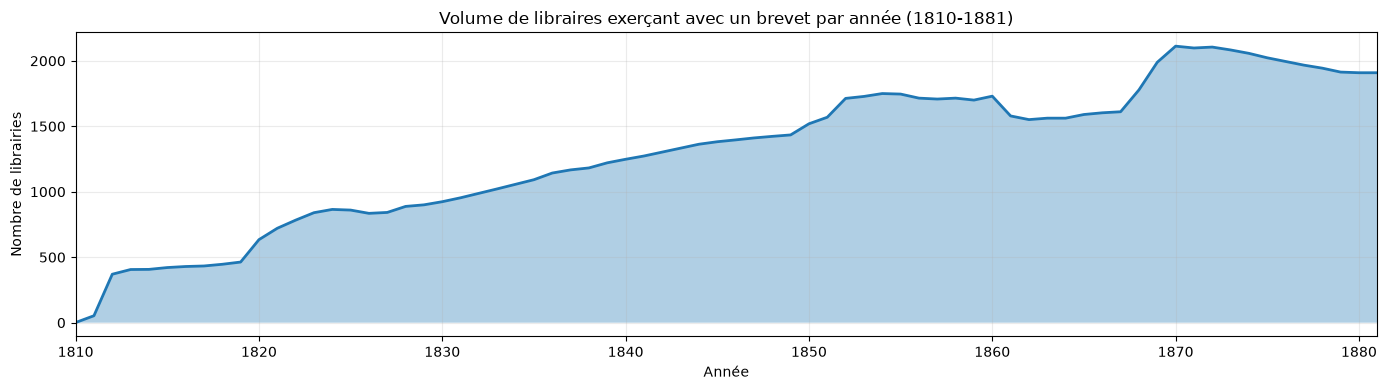

In [19]:
# Frise chronologique (épaisseur/hauteur = volume de librairies ouvertes)
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    %pip install matplotlib
    import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))
plt.fill_between(timeline["annee"], timeline["nb_librairies_ouvertes"], alpha=0.35)
plt.plot(timeline["annee"], timeline["nb_librairies_ouvertes"], linewidth=2)
plt.title("Volume de libraires exerçant avec un brevet par année (1810-1881)")
plt.xlabel("Année")
plt.ylabel("Nombre de librairies")
plt.xlim(1810, 1881)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()